# Previsão de Preços no E-commerce Brasileiro com Machine Learning: Base Olist

Machine Learning para Predição de Preços no E-commerce

Neste projeto, vou desenvolver um modelo de Machine Learning para estimar o preço de produtos em um marketplace. O projeto envolve aprendizado supervisionado para um problema de regressão, no qual a variável-alvo será o preço do produto.

Utilizarei a base pública da Olist, um marketplace brasileiro, contendo informações sobre produtos, vendedores, pedidos e outras características que podem ajudar a explicar as diferenças de preços.

Vou utilizar o seguinte pipeline:

1. Definição do problema de negócio.
2. Limpeza e pré-processamento dos dados.
3. Entendimento do problema e definição da estratégia de validação.
4. Divisão dos dados em conjuntos de treino e teste.
5. Exploração dos dados (EDA).
6. Treinamento dos modelos e ajuste de hiperparâmetros
7. Teste e avaliação final do modelo.
8. Interpretação dos resultados e geração de insights de negócio.
9. Deploy do modelo.

Neste notebook, realizaremos as etapas de 4 e 5 do projeto, com foco na análise exploratória dos dados (EDA). O principal objetivo é identificar padrões e características que ajudam a explicar as diferenças nos preços dos produtos.

### importando as bibliotecas

In [0]:
%pip install seaborn
import pandas as pd
import numpy as np
import seaborn as sns
import zipfile
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import unicodedata

Looking in indexes: [REDACTED]
Note: you may need to restart the kernel using %restart_python or dbutils.library.restartPython() to use updated packages.


### importando a base


In [0]:
# Carregando a base gold do projeto pricing
order_data = spark.table("olist.gold.projeto_pricing").toPandas()
order_data.shape

(111046, 17)

## 4. Divisão dos dados em conjuntos de treino e teste.

Antes de realizar o train-test split, é importante definir qual cenário de pricing o modelo deverá representar. Existem diferentes estratégias válidas, dependendo do objetivo.

Para produtos que já existem, caso o objetivo seja estimar quanto eles poderiam valer atualmente, uma divisão temporal pode ser mais adequada. Nesse caso, os dados mais antigos seriam utilizados para treinamento e os mais recentes para teste, simulando a previsão de preços futuros.

Já para produtos novos, podemos realizar uma divisão por product_id, garantindo que os produtos presentes no conjunto de teste não tenham sido observados durante o treinamento. Dessa forma, avaliamos a capacidade do modelo de estimar o preço de produtos que nunca foram vistos anteriormente, utilizando suas demais características.

Neste projeto, optei pelo cenário temporal, buscando avaliar como o modelo se comportaria ao realizar previsões para períodos futuros. Essa abordagem permite analisar não apenas a capacidade de previsão dos preços, mas também possíveis mudanças na composição do marketplace ao longo do tempo, como alterações na participação das diferentes categorias de produtos.

Essa estratégia é mais próxima de um cenário real de utilização de um modelo de pricing, no qual dados históricos são utilizados para apoiar decisões de precificação em períodos posteriores. Dessa forma, a divisão temporal permite uma avaliação mais realista da capacidade de generalização do modelo diante de mudanças que podem ocorrer ao longo do tempo.

In [0]:
order_data['order_purchase_timestamp'] = pd.to_datetime(order_data['order_purchase_timestamp'])
print(order_data['order_purchase_timestamp'].min(), order_data['order_purchase_timestamp'].max())

# volume de itens por mês
print(order_data.groupby(order_data['order_purchase_timestamp'].dt.to_period('M')).size())
# 3) novas colunas a partir da data
ts = order_data['order_purchase_timestamp']
order_data['purchase_month'] = ts.dt.month
order_data['purchase_dow'] = ts.dt.dayofweek               # 0 = segunda, 6 = domingo
order_data['purchase_week'] = ts.dt.isocalendar().week.astype(int)
order_data['purchase_is_weekend'] = (ts.dt.dayofweek >= 5).astype(int)

2016-09-04 21:15:19 2018-09-03 09:06:57
order_purchase_timestamp
2016-09       6
2016-10     361
2016-12       1
2017-01     941
2017-02    1893
2017-03    2937
2017-04    2613
2017-05    4040
2017-06    3520
2017-07    4458
2017-08    4833
2017-09    4757
2017-10    5249
2017-11    8543
2017-12    6162
2018-01    8000
2018-02    7552
2018-03    8082
2018-04    7899
2018-05    7882
2018-06    7055
2018-07    7045
2018-08    7216
2018-09       1
Freq: M, dtype: int64


In [0]:
order_data = order_data.sort_values('order_purchase_timestamp').reset_index(drop=True)

X = order_data.drop(columns=['price'])
y = order_data['price']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, shuffle=False
)

print("Treino:", X_train.shape, "Teste:", X_test.shape)
print("Treino:", X_train['order_purchase_timestamp'].min(), "até", X_train['order_purchase_timestamp'].max())
print("Teste:", X_test['order_purchase_timestamp'].min(), "até", X_test['order_purchase_timestamp'].max())

Treino: (88836, 20) Teste: (22210, 20)
Treino: 2016-09-04 21:15:19 até 2018-05-25 20:11:19
Teste: 2018-05-25 20:26:15 até 2018-09-03 09:06:57


In [0]:
proporcao = pd.concat([
    X_train['product_category_name'].value_counts(),
    X_test['product_category_name'].value_counts()
], axis=1)

proporcao.columns = ['Treino', 'Teste']
proporcao = proporcao.fillna(0)

proporcao['Total'] = proporcao['Treino'] + proporcao['Teste']
proporcao['% Treino'] = proporcao['Treino'] / proporcao['Total'] * 100
proporcao['% Teste'] = proporcao['Teste'] / proporcao['Total'] * 100
proporcao = proporcao.sort_values('Total')

print(proporcao[['Total', 'Treino', 'Teste', '% Treino', '% Teste']].to_string())

                                                  Total  Treino   Teste    % Treino    % Teste
product_category_name                                                                         
seguros_e_servicos                                  2.0       2     0.0  100.000000   0.000000
fashion_roupa_infanto_juvenil                       8.0       7     1.0   87.500000  12.500000
pc_gamer                                            9.0       5     4.0   55.555556  44.444444
la_cuisine                                         14.0      14     0.0  100.000000   0.000000
cds_dvds_musicais                                  14.0      14     0.0  100.000000   0.000000
portateis_cozinha_e_preparadores_de_alimentos      15.0       2    13.0   13.333333  86.666667
artes_e_artesanato                                 24.0       4    20.0   16.666667  83.333333
fashion_esporte                                    30.0      29     1.0   96.666667   3.333333
casa_conforto_2                                   

A análise da distribuição das categorias mostrou que algumas categorias apresentam proporções diferentes entre os conjuntos de treinamento e teste. Essas diferenças são mais acentuadas em categorias com poucas observações, nas quais pequenas alterações no número de registros provocam grandes variações percentuais. Entretanto, também foram observadas diferenças relevantes em categorias com maior volume de dados, indicando que parte dessa variação pode estar relacionada a mudanças reais na composição dos produtos ao longo do tempo.

Apesar dessas diferenças, optou-se por manter o split temporal, pois o objetivo do projeto é simular a previsão de preços em períodos futuros. Dessa forma, preservar a ordem cronológica dos dados é mais importante do que garantir uma distribuição idêntica das categorias entre treinamento e teste. Uma divisão aleatória ou estratificada poderia produzir conjuntos mais semelhantes, mas não representaria adequadamente o cenário real de previsão futura.

             treino         teste
count  88836.000000  22210.000000
mean     120.201907    123.003953
std      179.745761    197.049262
min        0.850000      2.200000
25%       39.900000     39.900000
50%       74.900000     75.000000
75%      134.900000    134.990000
90%      229.900000    227.243000
max     6735.000000   6729.000000


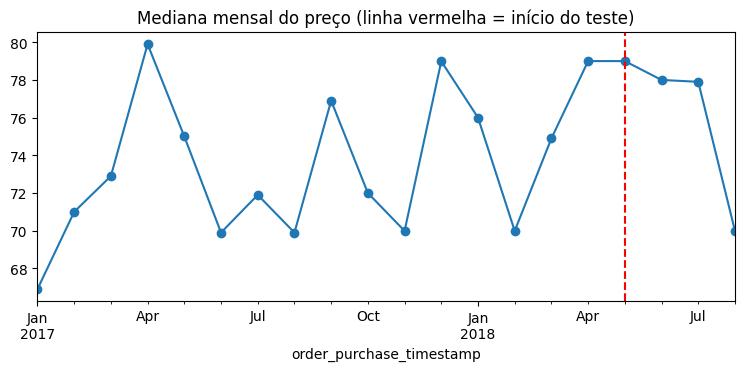

In [0]:
# 1) mediana e percentis do preço: treino vs teste
comparacao = pd.concat([
    y_train.describe(percentiles=[.25, .5, .75, .9]).rename('treino'),
    y_test.describe(percentiles=[.25, .5, .75, .9]).rename('teste'),
], axis=1)
print(comparacao)

# 2) mediana mensal ao longo de todo o período
import matplotlib.pyplot as plt

mensal = (order_data
          .groupby(order_data['order_purchase_timestamp'].dt.to_period('M'))['price']
          .median())
mensal = mensal.loc['2017-01':'2018-08']        # ignora 2016, que tem pouquíssimas linhas
mensal.plot(figsize=(9, 3.5), marker='o')
plt.axvline(pd.Period(X_test['order_purchase_timestamp'].min(), 'M'), color='red', linestyle='--')
plt.title('Mediana mensal do preço (linha vermelha = início do teste)')
plt.show()

**Consistência de preços entre treino e teste**

A comparação dos percentis mostra que a distribuição de preços é muito parecida nos dois conjuntos: a mediana ( 74,90 no treino e  75,00 no teste) e os quartis praticamente não mudam, e a média difere em cerca de 2%. A pequena diferença no desvio padrão vem da cauda de produtos caros, e não de uma mudança no nível geral de preços.

O gráfico da mediana mensal confirma esse resultado ao longo do tempo: a mediana oscila em torno de um patamar estável, sem tendência de alta ou queda e sem mudança de nível na passagem do treino para o teste (linha vermelha). Isso indica que o split temporal não introduz um desvio causado por mudança no patamar de preços, e que as variações mensais observadas são pequenas diante da dispersão dos preços.

Portanto, o conjunto de teste é consistente com o de treino quanto ao nível de preços, e é adequado para avaliar o modelo em um cenário de previsão futura.

## 5. Exploração dos dados (EDA)


In [0]:
X_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 88836 entries, 0 to 88835
Data columns (total 20 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   seller_id                      88836 non-null  object        
 1   product_id                     88836 non-null  object        
 2   freight_value                  88836 non-null  float64       
 3   order_purchase_timestamp       88836 non-null  datetime64[ns]
 4   product_category_name          88836 non-null  object        
 5   product_name_length            88836 non-null  int32         
 6   product_description_length     88836 non-null  int32         
 7   product_photos_qty             88836 non-null  int32         
 8   product_weight_g               88836 non-null  float64       
 9   product_length_cm              88836 non-null  float64       
 10  product_height_cm              88836 non-null  float64       
 11  product_width_cm    

In [0]:
# extra_cat são as features categóricas disfarçadas de numéricas
extra_cat = ['purchase_month', 'purchase_dow', 'purchase_week']
cat_feat = X_train.select_dtypes(include='object').columns.tolist() + extra_cat
num_feat = [c for c in X_train.select_dtypes(include='number').columns if c not in extra_cat]
print(f"Existem {len(cat_feat)} variáveis categóricas: {cat_feat}")
print(f"Existem {len(num_feat)} variáveis numéricas: {num_feat}")
# a coluna 'order_purchase_timestamp' não entra diretamente em `X`, pois o formato datetime não é aceito pelos modelos.
# A informação da data entra no modelo pelas colunas `purchase_month`, `purchase_dow`, `purchase_week` e `purchase_is_weekend` 

Existem 10 variáveis categóricas: ['seller_id', 'product_id', 'product_category_name', 'product_category_name_english', 'seller_zip_code_prefix', 'seller_city', 'seller_state', 'purchase_month', 'purchase_dow', 'purchase_week']
Existem 9 variáveis numéricas: ['freight_value', 'product_name_length', 'product_description_length', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'purchase_is_weekend']


In [0]:
order_data.nunique()

seller_id                         3035
product_id                       32340
price                             5901
freight_value                     6977
order_purchase_timestamp         96741
product_category_name               73
product_name_length                 66
product_description_length        2960
product_photos_qty                  19
product_weight_g                  2202
product_length_cm                   99
product_height_cm                  102
product_width_cm                    95
product_category_name_english       71
seller_zip_code_prefix            2211
seller_city                        604
seller_state                        23
purchase_month                      12
purchase_dow                         7
purchase_week                       52
purchase_is_weekend                  2
dtype: int64

## Target ('Price')

### histograma do Price

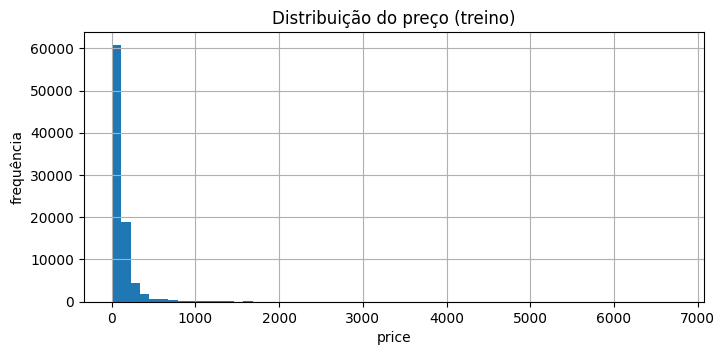

In [0]:
y_train.hist(bins=60, figsize=(8, 3.5))
plt.title('Distribuição do preço (treino)')
plt.xlabel('price')
plt.ylabel('frequência')
plt.show()

Distribuição do preço

O histograma mostra uma distribuição fortemente assimétrica à direita: a maior parte dos itens está concentrada nas faixas mais baixas de preço, e poucos produtos muito caros formam uma cauda longa. 

Em modelos que minimizam o erro quadrático, poucos itens caros podem dominar o treinamento. Aplicar o logaritmo ao preço comprime a cauda e pode ajudar alguns modelos, principalmente os lineares. Os modelos baseados em árvores não exigem simetria no alvo, então o ganho deles pode ser menor. 

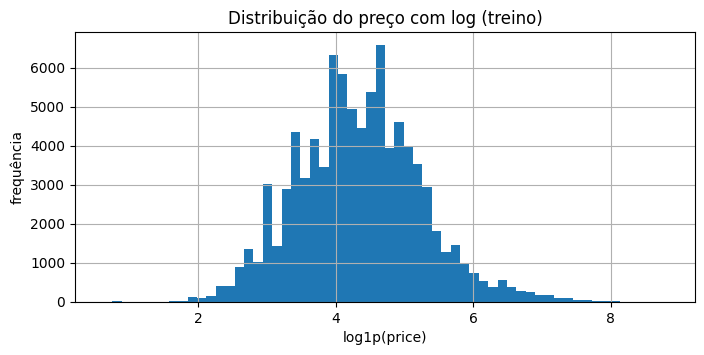

In [0]:
np.log1p(y_train).hist(bins=60, figsize=(8, 3.5))
plt.title('Distribuição do preço com log (treino)')
plt.xlabel('log1p(price)')
plt.ylabel('frequência')
plt.show()

Com o log, a distribuição fica muito mais simétrica, próxima de um formato de sino, e a cauda longa é comprimida. Os picos que aparecem no histograma correspondem a preços redondos muito usados pelos vendedores. Isso reforça a hipótese de que a transformação pode ajudar alguns modelos

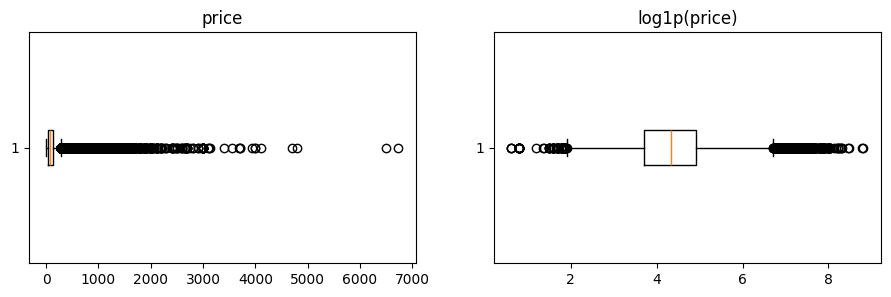

limite superior (IQR): 277.4
itens acima do limite: 6695 (7.5%)
itens acima do p99: 889
10 maiores preços: [6735.   6499.   4799.   4690.   4099.99 3999.9  3999.   3930.   3700.
 3699.99]


In [0]:
# 1) boxplot (sem log e com log)
fig, ax = plt.subplots(1, 2, figsize=(11, 3))
ax[0].boxplot(y_train, vert=False);           ax[0].set_title('price')
ax[1].boxplot(np.log1p(y_train), vert=False); ax[1].set_title('log1p(price)')
plt.show()

# 2) regra do IQR e itens mais caros
q1, q3 = y_train.quantile([.25, .75])
limite = q3 + 1.5 * (q3 - q1)
print("limite superior (IQR):", limite)
print("itens acima do limite:", (y_train > limite).sum(), f"({(y_train > limite).mean():.1%})")
print("itens acima do p99:", (y_train > y_train.quantile(.99)).sum())
print("10 maiores preços:", y_train.nlargest(10).values)

Os outliers de preço não serão removidos: os valores mais altos parecem corresponder a produtos caros legítimos, e removê-los impediria o modelo de precificar esse tipo de item. 

In [0]:
train_full = order_data.loc[X_train.index]
print(train_full.nlargest(10, 'price')[['price', 'product_category_name', 'product_weight_g', 'freight_value']])

         price   product_category_name  product_weight_g  freight_value
2204   6735.00   utilidades_domesticas           30000.0         194.31
11911  6499.00                   artes            7400.0         227.66
6170   4799.00         eletroportateis           22600.0         151.34
7503   4690.00         eletroportateis           30000.0          74.34
73399  4099.99          consoles_games            3050.0          75.27
4887   3999.90      relogios_presentes             800.0          17.01
7509   3999.00         eletroportateis           20500.0         195.76
86067  3930.00      ferramentas_jardim            5650.0          49.55
71418  3700.00      relogios_presentes             800.0          92.59
2047   3699.99  informatica_acessorios            4300.0          36.23


Para confirmar que os preços extremos fazem sentido, os 10 maiores preços do treino foram comparados com a categoria, o peso e o frete de cada item. Os preços altos correspondem a categorias plausíveis para itens caros (eletroportáteis, utilidades domésticas, consoles e relógios), e os produtos mais pesados (20 a 30 kg) têm frete alto. Mas o frete varia bastante com o destino (um console de 3 kg tem frete de 75,27 e um relógio de 800 g tem 92,59, contra uma mediana de 16,11), então ele não serve para validar o preço. Não há indício claro de erro de cadastro, então os outliers de preço serão mantidos.

## Análise Univariada

### Numéricas

                              count         mean  ...      75%       max
freight_value               88836.0    19.563038  ...    20.66    409.68
product_name_length         88836.0    48.671597  ...    57.00     72.00
product_description_length  88836.0   779.057499  ...   973.00   3992.00
product_photos_qty          88836.0     2.209071  ...     3.00     20.00
product_weight_g            88836.0  2165.501058  ...  1850.00  40425.00
product_length_cm           88836.0    30.658978  ...    39.00    105.00
product_height_cm           88836.0    16.831476  ...    20.00    105.00
product_width_cm            88836.0    23.275541  ...    30.00    118.00
purchase_is_weekend         88836.0     0.225967  ...     0.00      1.00

[9 rows x 8 columns]
freight_value                 5.55
product_weight_g              3.54
product_height_cm             2.23
product_description_length    2.06
product_photos_qty            1.95
product_width_cm              1.73
product_length_cm             1.72
pur

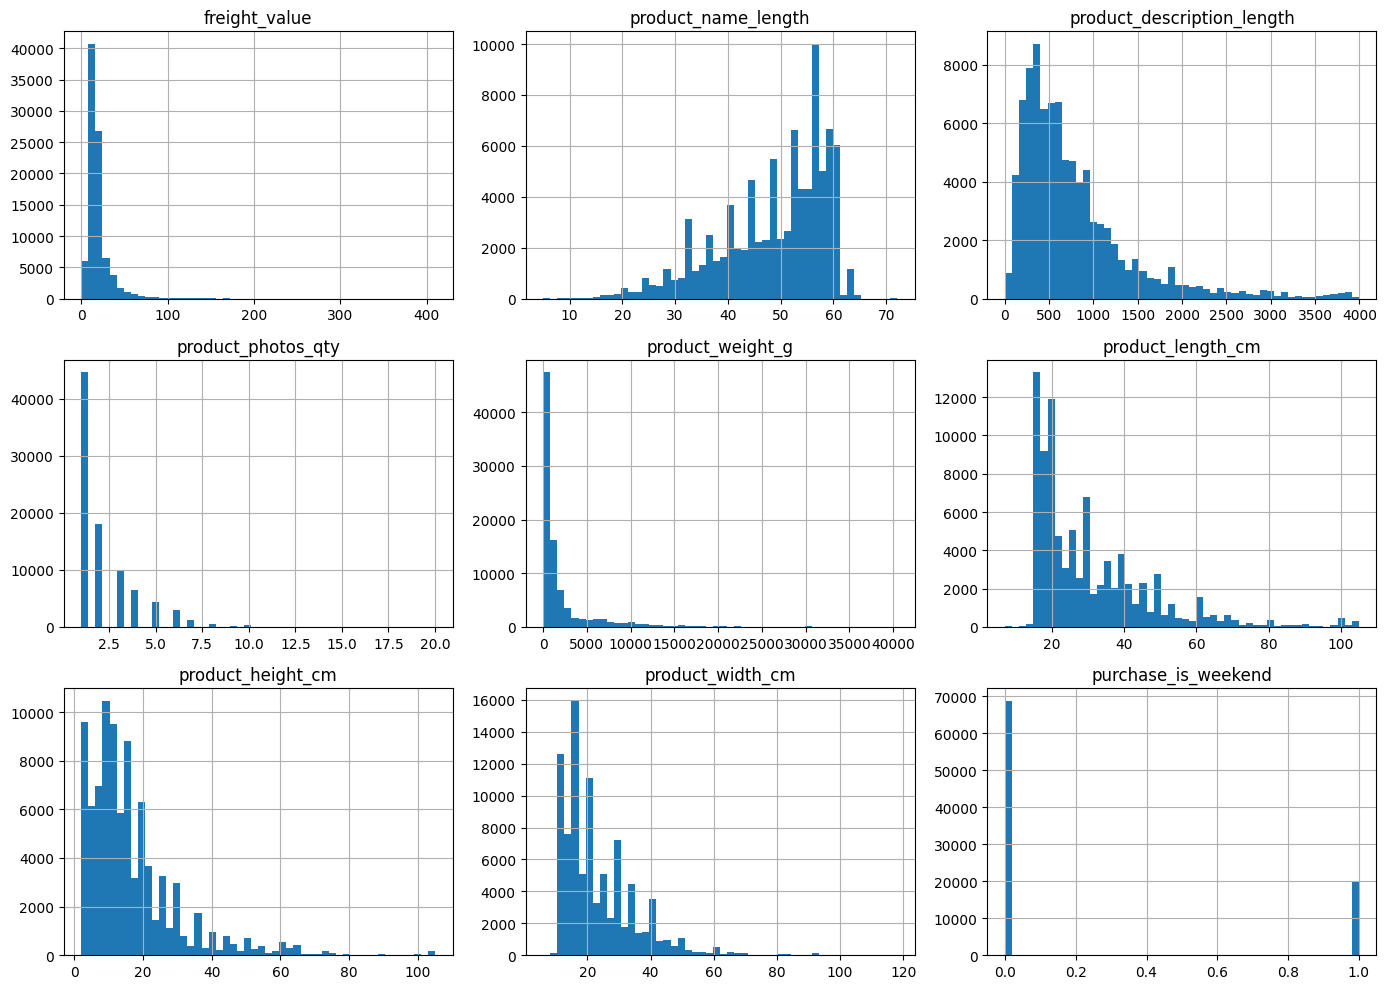

In [0]:


# 1) resumo numérico de todas as numéricas
print(X_train[num_feat].describe().T)

# 2) assimetria de cada uma
print(X_train[num_feat].skew().sort_values(ascending=False).round(2))

# 3) quantos zeros em cada uma (valores suspeitos)
print((X_train[num_feat] == 0).sum())

# 4) painel de histogramas
fig, axes = plt.subplots(3, 3, figsize=(14, 10))
for ax, col in zip(axes.flat, num_feat):
    X_train[col].hist(bins=50, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Principais insights da análise univariada numérica**

- **Qualidade dos dados:** nenhuma variável numérica tem valores nulos. Peso e dimensões não têm zeros nem valores impossíveis: os máximos (105 a 118 cm e 40 kg) são coerentes com produtos grandes, e os mínimos (peso de 2 g, altura de 2 cm) são plausíveis. O único zero relevante é o frete, com 376 itens (0,4%), provavelmente fretes grátis.
- **Frete (`freight_value`):** a variável mais assimétrica (skew 5,55). A maioria dos itens tem frete baixo (mediana de  16,11, percentil 95 de  43,16), e poucos itens grandes ou com destino distante esticam a cauda à direita, de forma parecida com o preço. O máximo chega a 409,68, e 10,7% das linhas são outliers pelo IQR.
- **Peso (`product_weight_g`):** a segunda mais assimétrica (skew 3,54) e a que tem mais outliers (14,3%). A maioria dos produtos é leve (mediana de 700 g, 59% até 1 kg), mas a média sobe para 2.166 g por causa de poucos itens pesados (cerca de 5% passam de 10 kg).
- **Dimensões (comprimento, altura, largura):** assimetria moderada, também à direita (1,7 a 2,2). As medianas são 25, 13 e 20 cm. Os histogramas têm picos em valores específicos (por exemplo, 14,8% dos comprimentos são exatamente 16 cm, e cerca de 36% a 39% das medidas são múltiplos de 5), o que sugere o uso de tamanhos padronizados de embalagem. O volume calculado é ainda mais assimétrico (skew 3,98, mediana de 6.900 cm³ e máximo de 294.000 cm³). Dimensões, volume e peso devem ser parcialmente redundantes, o que vale checar na bivariada.
- **Quantidade de fotos:** assimetria moderada à direita (1,95). 50,2% dos produtos têm 1 foto e 75% têm 3 ou menos, e só 0,5% têm 10 ou mais (máximo de 20). Com poucos valores distintos e cauda curta, pode ser tratada como ordinal ou com limite superior.
- **Tamanho do nome (`product_name_lenght`):** a única levemente inclinada para a esquerda (-0,88). A maior parte dos nomes tem entre 40 e 60 caracteres (mediana de 51), e o percentil 95 de 60 sugere um limite em torno desse valor. Os poucos outliers (0,7%) são nomes muito curtos.
- **Tamanho da descrição (`product_description_lenght`):** assimetria moderada à direita (2,06). A mediana é 594 caracteres e a média 779, com cauda de descrições longas (percentil 95 de 2.115 e 6,3% de outliers).
- **Perfil típico dos produtos:** pequenos e leves, com poucas fotos (mediana de 1 foto, peso de 700 g e comprimento de 25 cm).
- **Variável binária (`purchase_is_weekend`):** cerca de 77% das compras ocorrem em dias de semana e 23% no fim de semana, o que é coerente com a queda de sábado e domingo vista no dia da semana.

**Implicações para a modelagem:** os modelos baseados em árvores não exigem simetria nas features, mas, nos modelos lineares, será interessante aplicar a transformação logarítmica nas variáveis mais assimétricas, principalmente frete e peso (e também volume e tamanho da descrição). Em log, o skew do frete cai para -0,2 e o do peso para 0,44. Os outliers parecem legítimos (produtos grandes, pesados ou com destino distante) e não erros de registro, então não os removeria automaticamente.

**Dimensões do produto.** Comprimento, altura e largura descrevem o tamanho físico do produto. Pode ser interessante criar uma variável de volume (comprimento × altura × largura), que resume esse tamanho em um único valor.

count     88836.0
mean      15839.0
std       24126.0
min         288.0
25%        2880.0
50%        6900.0
75%       19448.0
99%      115584.0
max      294000.0
Name: product_volume_cm3, dtype: float64
skew: 3.9793330994036147


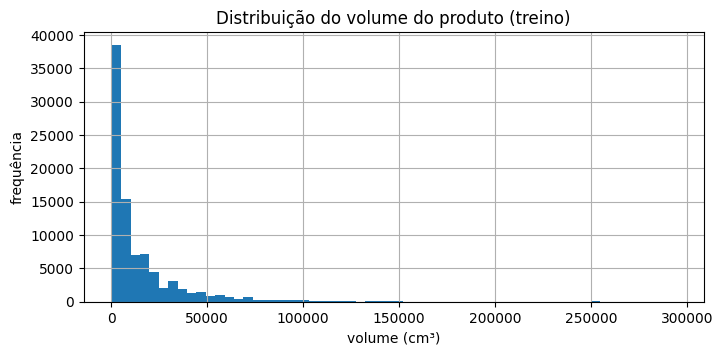

In [0]:
#possivel nova feature (Volume)
X_train['product_volume_cm3'] = (
    X_train['product_length_cm'] * X_train['product_height_cm'] * X_train['product_width_cm']
)

print(X_train['product_volume_cm3'].describe(percentiles=[.25, .5, .75, .99]).round(0))
print("skew:", X_train['product_volume_cm3'].skew())

X_train['product_volume_cm3'].hist(bins=60, figsize=(8, 3.5))
plt.title('Distribuição do volume do produto (treino)')
plt.xlabel('volume (cm³)')
plt.ylabel('frequência')
plt.show()

### categóricas

In [0]:
linhas = []
for col in cat_feat:
    vc = X_train[col].value_counts()
    raros = vc[vc < 5]
    linhas.append({
        'variavel': col,
        'n_unicos': len(vc),
        'valor_mais_comum': vc.index[0],
        '% do mais comum': round(vc.iloc[0] / len(X_train) * 100, 1),
        '% dos 10 maiores': round(vc.head(10).sum() / len(X_train) * 100, 1),
        'n_raros (<5)': len(raros),
        '% linhas raros': round(raros.sum() / len(X_train) * 100, 1),
    })

resumo_cat = pd.DataFrame(linhas).sort_values('n_unicos').set_index('variavel')
print(resumo_cat.to_string())

                               n_unicos                  valor_mais_comum  % do mais comum  % dos 10 maiores  n_raros (<5)  % linhas raros
variavel                                                                                                                                  
purchase_dow                          7                                 0             16.3             100.0             0             0.0
purchase_month                       12                                 5             12.4              91.0             0             0.0
seller_state                         23                                SP             71.6              99.0             2             0.0
purchase_week                        52                                47              3.9              31.6             0             0.0
product_category_name_english        71                    bed_bath_table             10.1              64.7             2             0.0
product_category_name      

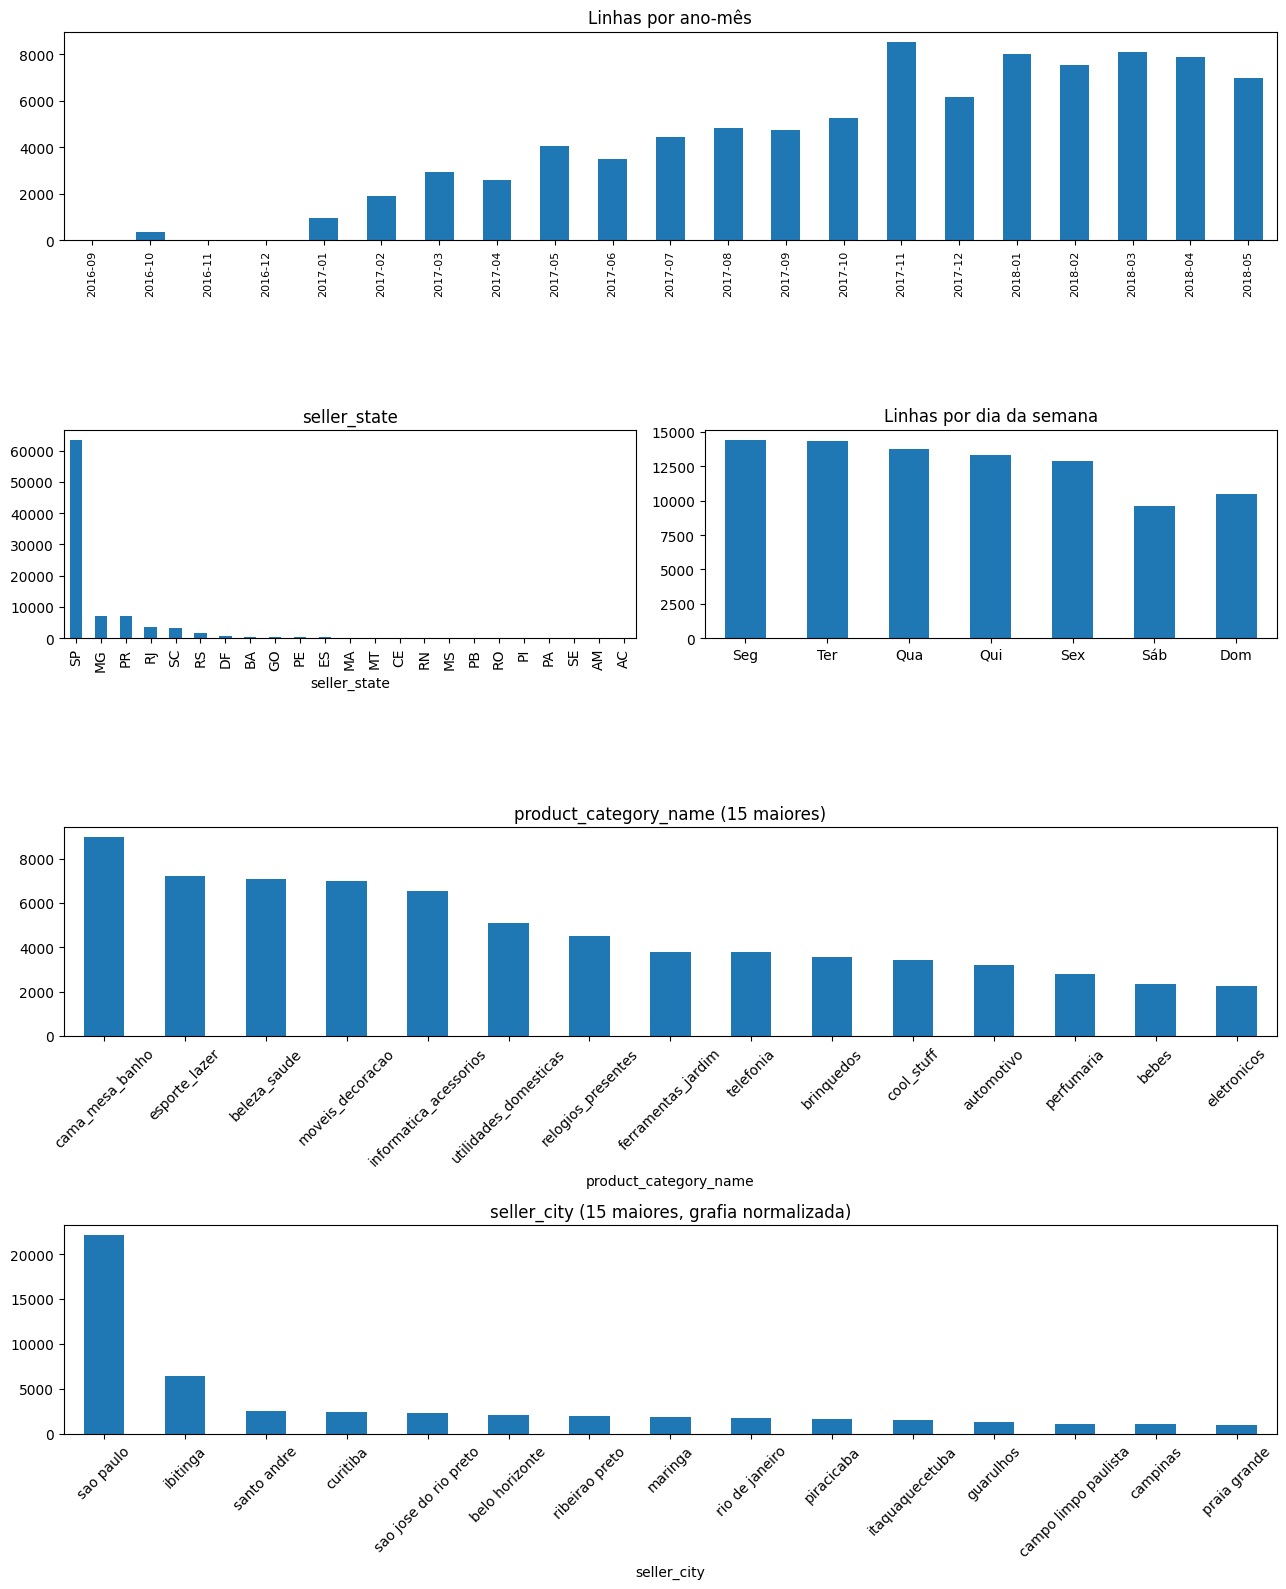

In [0]:

# 1) linhas por ano-mês (a data vem do order_data, pelo índice do treino)
datas_treino = order_data.loc[X_train.index, 'order_purchase_timestamp']
por_mes = datas_treino.dt.to_period('M').value_counts().sort_index()
meses = pd.period_range(por_mes.index.min(), por_mes.index.max(), freq='M')
por_mes = por_mes.reindex(meses, fill_value=0)       # meses sem dados ficam com 0
por_mes.index = por_mes.index.astype(str)

# 2) estado do vendedor
por_estado = X_train['seller_state'].value_counts()

# 3) dia da semana, com etiquetas (0 = segunda)
dias = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
por_dow = X_train['purchase_dow'].astype(int).value_counts().reindex(range(7), fill_value=0)
por_dow.index = dias

# 4) categoria de produto (15 maiores)
por_cat = X_train['product_category_name'].value_counts().head(15)

# 5) cidade do vendedor (15 maiores), com grafia normalizada
def normaliza(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode()
    return s.lower().strip()

cidades = X_train['seller_city']
cidades_norm = cidades.map(normaliza)
por_cidade = cidades_norm.value_counts().head(15)

# --- painel ---
fig, axes = plt.subplot_mosaic(
    [['mes', 'mes'],
     ['estado', 'dow'],
     ['cat', 'cat'],
     ['cidade', 'cidade']],
    figsize=(13, 16)
)

por_mes.plot(kind='bar', ax=axes['mes'], title='Linhas por ano-mês')
axes['mes'].tick_params(axis='x', rotation=90, labelsize=8)

por_estado.plot(kind='bar', ax=axes['estado'], title='seller_state')

por_dow.plot(kind='bar', ax=axes['dow'], title='Linhas por dia da semana')
axes['dow'].tick_params(axis='x', rotation=0)

por_cat.plot(kind='bar', ax=axes['cat'], title='product_category_name (15 maiores)')
axes['cat'].tick_params(axis='x', rotation=45)

por_cidade.plot(kind='bar', ax=axes['cidade'], title='seller_city (15 maiores, grafia normalizada)')
axes['cidade'].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

A base não tem pedidos entre 11/out/2016 e 4/jan/2017 (novembro com zero e dezembro com apenas 1). Conferi os CSVs originais, sem filtros nem merges, e o buraco já está lá, então não é erro do meu código. Pesquisei na internet e outras análises da base da Olist relatam o mesmo problema, sem explicação oficial. Por isso trato como uma limitação da fonte e uso o período de jan/2017 a ago/2018 na análise de tendência. Como 2016 tem só cerca de 0,3% das linhas, o teste (2018) não é afetado.

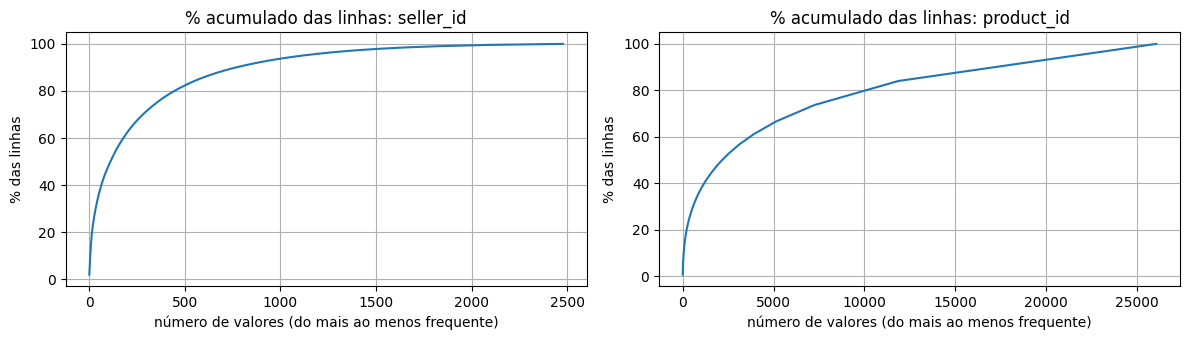

vendedores para cobrir 80% das linhas: 446
Linhas do teste com produto já visto no treino: 55.8%
Linhas do teste com produto novo: 44.2%


In [0]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
for ax, col in zip(axes, ['seller_id', 'product_id']):
    acumulado = X_train[col].value_counts(normalize=True).cumsum().values
    ax.plot(range(1, len(acumulado) + 1), acumulado * 100)
    ax.set_title(f'% acumulado das linhas: {col}')
    ax.set_xlabel('número de valores (do mais ao menos frequente)')
    ax.set_ylabel('% das linhas')
    ax.grid(True)
plt.tight_layout()
plt.show()

# quantos vendedores cobrem 80% das linhas
acum_vend = X_train['seller_id'].value_counts(normalize=True).cumsum()
print("vendedores para cobrir 80% das linhas:", (acum_vend < 0.8).sum() + 1)
vistos = X_test['product_id'].isin(X_train['product_id']).mean()
print(f"Linhas do teste com produto já visto no treino: {vistos:.1%}")
print(f"Linhas do teste com produto novo: {1 - vistos:.1%}")

**Principais insights da análise univariada categórica**

- **Tempo:** o volume de linhas cresce ao longo do período, de cerca de 900 em jan/2017 para cerca de 8 mil por mês em 2018. Novembro de 2017 se destaca (8.543 linhas, contra 5.249 em outubro e 6.162 em dezembro), provavelmente por causa da Black Friday. Como o treino vai até maio/2018, os meses de jan a mai aparecem duas vezes e os de jun a dez só uma vez. Por isso `purchase_month` mistura sazonalidade com o crescimento da plataforma: maio é o mês mais comum (12,4%) por causa disso, não por ser um mês forte. Os meses do teste (jun a ago) foram vistos no treino só em 2017, quando o volume era menor.
- **Dia da semana:** de segunda a sexta o volume é parecido (14,5% a 16,3% por dia) e cai no fim de semana (sábado 10,8% e domingo 11,8%). Segunda é o dia mais forte.
- **Categoria de produto:** são 73 categorias, sem dominância. A maior (`cama_mesa_banho`) tem 10,1%, as 5 maiores somam 41,4% e as 10 maiores 64,7%. Há uma cauda longa: 22 categorias têm menos de 100 linhas.
- **Estado do vendedor:** há forte concentração em SP (71,6%), seguido de MG (8,0%), PR (7,8%) e RJ (4,0%). Os 10 maiores estados somam 99% das linhas.
- **Cidade e CEP do vendedor:** São Paulo concentra 24,9% das linhas e Ibitinga 7,2%, que coincide com o CEP prefixo 14940 (7,2%). São 538 cidades (164 com menos de 5 linhas) e 1.884 prefixos de CEP (663 raros). Cidade, CEP e estado carregam a mesma informação em níveis diferentes de detalhe, então não faz sentido usar todos juntos sem critério. A cidade também tem grafias inconsistentes.
- **Vendedor:** são 2.477 vendedores e nenhum passa de 2,0% das
- linhas. Os 10 maiores somam 15,3% e 446 vendedores (cerca de 18%) cobrem 80% das linhas. Ainda assim, 995 vendedores têm menos de 5 linhas.
- **Produto:** são 26.078 produtos e nenhum passa de 0,6% das linhas. Cerca de 14 mil aparecem uma única vez, e 39,1% das linhas são de produtos com menos de 5 vendas. É a variável de maior cardinalidade e a de pior cobertura, ainda mais porque cerca de 44% das linhas do teste são de produtos que o treino nunca viu.

**Implicações para a modelagem:** variáveis de baixa cardinalidade (`seller_state`, `purchase_dow`, `purchase_month`) podem usar one-hot. As de alta cardinalidade (`product_id`, `seller_id`, `seller_city`, `seller_zip_code_prefix`, `purchase_week`) pedem um tratamento especial, como target ou frequency encoding, ou agrupar os valores raros em "outros". A categoria de produto fica no meio-termo, com one-hot ou agrupando as menores.

## Análise Bivariada

### Matrix de correlação

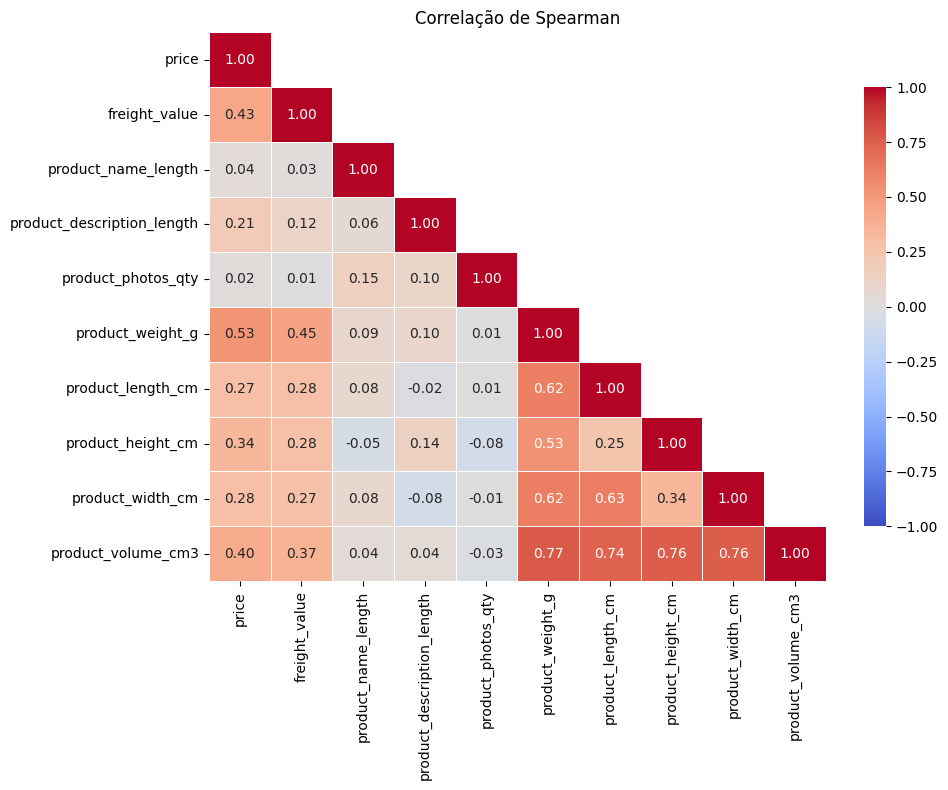

In [0]:
# num_feat sem a binária (purchase_is_weekend), e com o volume se ele ainda não estiver na lista
cols_corr = [c for c in num_feat if c != 'purchase_is_weekend']
if 'product_volume_cm3' in X_train.columns and 'product_volume_cm3' not in cols_corr:
    cols_corr.append('product_volume_cm3')
df_corr = X_train[cols_corr].copy()
df_corr.insert(0, 'price', y_train)          # preço na primeira linha/coluna

corr = df_corr.corr(method='spearman')
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)

plt.figure(figsize=(10, 8))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            center=0, vmin=-1, vmax=1, linewidths=.5, cbar_kws={'shrink': .8})
plt.title('Correlação de Spearman')
plt.tight_layout()
plt.show()

**Principais insights da matriz de correlação (Spearman)**


- **Tamanho físico é o sinal mais forte:** produtos mais pesados e maiores tendem a ser mais caros, e o peso é a variável mais informativa entre as numéricas.
- **Variáveis de anúncio quase não ajudam:** tamanho do nome (0,04) e quantidade de fotos (0,02) praticamente não têm relação com o preço. O tamanho da descrição tem uma relação pequena (0,21).
- **Relação crescente, mas não linear:** o Spearman fica acima do Pearson no peso (0,53 contra 0,34) e no volume (0,40 contra 0,30), o que indica que a relação existe, mas é curva e distorcida pela cauda pesada. Isso reforça o uso do log nesses casos.
- **Forte redundância entre tamanho físico:** o volume tem correlação de 0,74 a 0,76 com cada dimensão e de 0,77 com o peso. O peso também se correlaciona com as dimensões (0,53 a 0,62), e comprimento e largura entre si (0,63). Peso, volume e dimensões carregam informação parecida.
- **Frete:** correlaciona com o peso (0,45) e com o preço (0,43)

**Implicações:** nos modelos lineares, vale usar peso e volume e deixar as dimensões de fora (ou o contrário) para reduzir a multicolinearidade. Os modelos de árvore lidam melhor com essa redundância. 

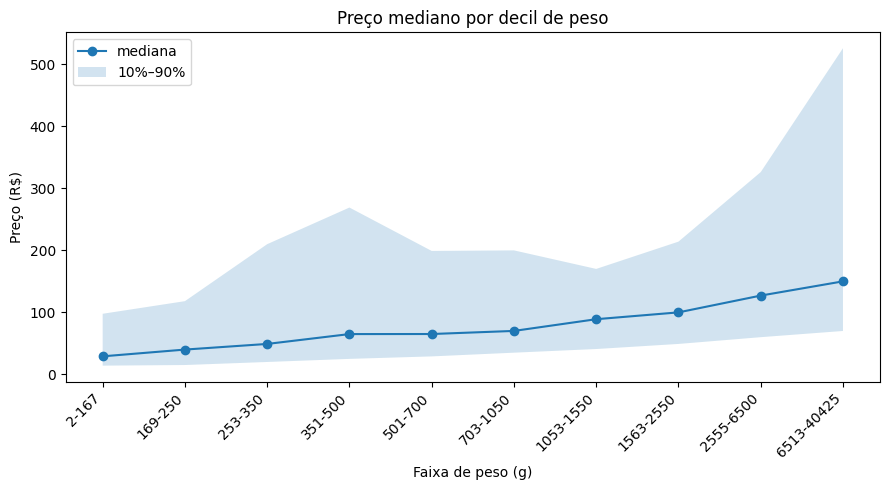

In [0]:
d = X_train[['product_weight_g']].copy()
d['price'] = y_train
d['faixa'] = pd.qcut(d.product_weight_g, 10, duplicates='drop')

g = d.groupby('faixa', observed=True).agg(
    med=('price', 'median'),
    q1=('price', lambda x: x.quantile(.10)),
    q3=('price', lambda x: x.quantile(.90)),
    pmin=('product_weight_g', 'min'),
    pmax=('product_weight_g', 'max'))

x = np.arange(len(g))
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(x, g.med, marker='o', label='mediana')
ax.fill_between(x, g.q1, g.q3, alpha=.2, label='10%–90%')
ax.set_xticks(x)
ax.set_xticklabels([f"{int(a)}-{int(b)}" for a, b in zip(g.pmin, g.pmax)], rotation=45, ha='right')
ax.set_xlabel('Faixa de peso (g)'); ax.set_ylabel('Preço (R$)')
ax.set_title('Preço mediano por decil de peso'); ax.legend()
plt.tight_layout(); plt.show()

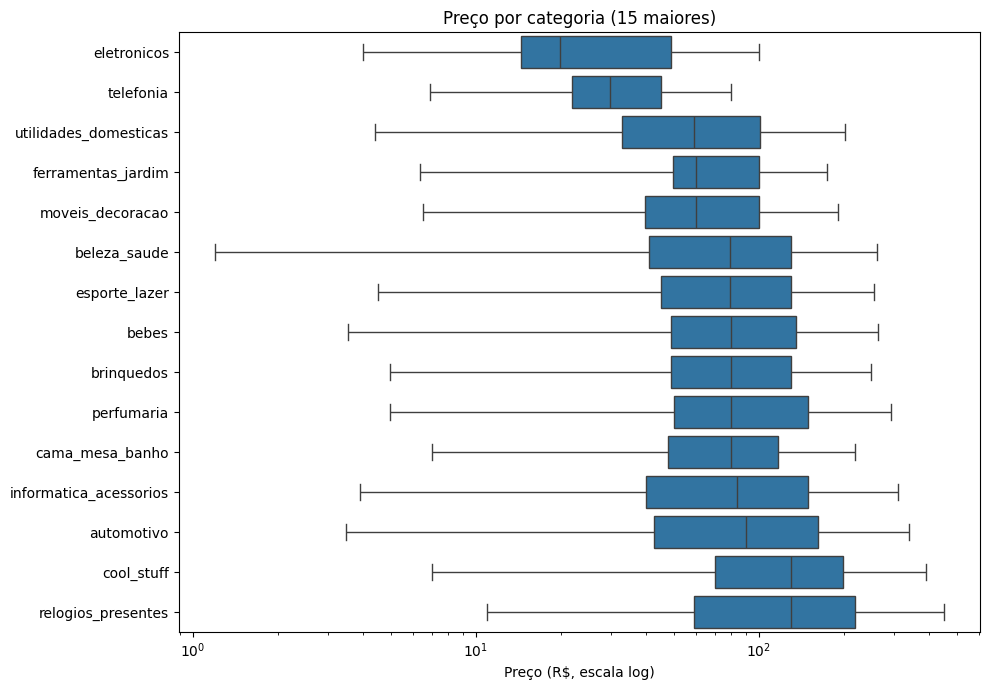

In [0]:
d = X_train.copy(); d['price'] = y_train
top = d.product_category_name.value_counts().head(15).index
d = d[d.product_category_name.isin(top)]
ordem = d.groupby('product_category_name').price.median().sort_values().index

plt.figure(figsize=(10, 7))
sns.boxplot(data=d, y='product_category_name', x='price', order=ordem, showfliers=False)
plt.xscale('log')
plt.xlabel('Preço (R$, escala log)'); plt.ylabel('')
plt.title('Preço por categoria (15 maiores)')
plt.tight_layout(); plt.show()

**Principais insights da análise bivariada: correlação, peso e categoria vs preço (treino)**

- **Correlação com o preço:** nenhuma variável numérica passa de 0,53. O peso é a mais forte (0,53), seguido de frete (0,43) e volume (0,40). Tamanho do nome (0,04) e quantidade de fotos (0,02) praticamente não têm relação com o preço.
- **Frete:** correlaciona com o peso (0,45), com o preço (0,43) e com o volume (0,37), ou seja, ele reflete em parte o tamanho do produto. Também só é conhecido depois que o destino do cliente é definido.
- **Redundância entre tamanho físico:** o volume tem correlação de 0,77 com o peso e de 0,74 a 0,76 com cada dimensão, e as dimensões se correlacionam entre si (0,25 a 0,63). Peso, volume e dimensões carregam informação parecida.
- **Variáveis de anúncio:** nome, descrição e fotos têm correlações fracas entre si (no máximo 0,15), então não há redundância relevante nesse grupo.
- **Peso:** o preço mediano cresce com o peso, de 29,00 (até 167 g) para 149,90 (acima de 6,5 kg), mas não é uma reta: entre 350 g e 1 kg a mediana quase estaciona (65,00 a 70,00) e volta a subir depois.
- **Peso sobe o "piso" do preço:** o percentil 10 aumenta de forma contínua, de 14,00 para 69,90, ou seja, produtos pesados raramente são baratos. O percentil 90 oscila mais (entre 170,00 e 270,00 de 250 g a 2,5 kg) e só dispara nos mais pesados (526,00).
- **Muita dispersão em todas as faixas de peso:** o percentil 90 é de 4 a 11 vezes o percentil 10 (de 4,2 vezes entre 1 e 1,5 kg a 10,8 vezes entre 350 e 500 g). O peso sozinho não determina o preço.
- **Categoria:** as medianas vão de 19,90 (`eletronicos`) a 130,00 (`cool_stuff` e `relogios_presentes`), cerca de 6,5 vezes. `eletronicos` e `telefonia` são as mais baratas, e a maioria das categorias grandes tem medianas entre 59,00 e 90,00.
- **Muita variação dentro de cada categoria:** nas 15 maiores, o 75% do preço é de 2 a 3,8 vezes o 25% (mediana de 2,9 vezes). Só as categorias dos extremos se separam bem (o 75% de `eletronicos`, 49,00 , fica abaixo do 25% de `cool_stuff`, 69,90), e as do meio se sobrepõem bastante. O gráfico não mostra os outliers (`showfliers=False`), que estendem ainda mais essa variação.

**Observação sobre o método:** usei o Spearman porque o Pearson mede só relações em linha reta e é sensível às caudas pesadas, então tende a subestimar as relações com o preço (por exemplo, o peso tem 0,34 no Pearson e 0,53 no Spearman).

**Implicações para a modelagem:**
- Peso e volume devem entrar em escala log, porque a relação com o preço é crescente, mas não linear.
- Nos modelos lineares, vale usar peso e volume e deixar as dimensões de fora (ou o contrário), por causa da redundância. Os modelos de árvore lidam melhor com isso.
- O frete precisa de uma decisão: ele tem sinal, mas depende do destino do cliente.
- Nome e fotos são candidatas a menor prioridade.
- A categoria ajuda, mas sozinha não basta, já que a variação dentro dela é grande.

## Conclusões da EDA

- **Dados e validação:** após a limpeza ficaram 111.046 linhas (valores em reais). Não há pedidos entre 11/out/2016 e 4/jan/2017 (limitação da fonte), então a análise de tendência usa jan/2017 a ago/2018. O split é temporal: treino até 25/mai/2018 e teste de 25/mai a 3/set/2018.
- **Preço:** muito assimétrico à direita (mediana de 74,90, média de 120,20 e máximo de 6.735), e o log deixa a distribuição próxima de um sino. Os preços altos parecem legítimos, então os outliers foram mantidos.
- **Variáveis:** frete e peso são as mais assimétricas, e peso, volume e dimensões são redundantes entre si. Peso (0,53), frete (0,43) e volume (0,40) são as mais ligadas ao preço, mas nenhuma explica o preço sozinha. Nome e fotos quase não têm relação (0,04 e 0,02). A categoria separa bem só os extremos, e dentro de cada uma o preço varia muito.
- **Categóricas:** `product_id`, `seller_id`, CEP e cidade têm alta cardinalidade e muitos valores raros
- **Treino × teste:** o nível de preço é estável (mediana de 74,90 e 75,00). No entanto, **44,1% das linhas do teste são de produtos que o treino nunca viu** — o modelo não pode depender de `product_id` para generalizar e precisa funcionar com base nas características do produto (peso, categoria, dimensões, etc.).
- **(vale testar):** comparar o modelo com `log1p(price)` e com o preço original, e usar log em frete, peso e volume, principalmente nos modelos lineares. Pode valer usar peso e volume no lugar das dimensões, que são redundantes. Também vale comparar com e sem o frete, já que ele só é conhecido depois que o destino é definido. 